# Porównanie dense angle encoding z feature reuploading

In [1]:
import numpy as np
from tqdm.notebook import tqdm
from sklearn.preprocessing import MinMaxScaler

## Przygotowanie danych

In [47]:
import kagglehub
battery_dataset = kagglehub.dataset_load(kagglehub.KaggleDatasetAdapter.PANDAS, 'vinay24baghira/ev-battery-health-and-degradation-dataset', 'ev_battery_health.csv')

In [271]:
features = [
    'state_of_health_pct', 'capacity_fade_pct', 'pack_capacity_kwh',
    'internal_resistance_mohm', 'cycle_count', 'battery_age_days'
]
target_feature = 'remaining_useful_life_cycles'
target_treshold = 800

In [272]:
from sklearn.model_selection import train_test_split

battery_ds = battery_dataset[features + [target_feature]].dropna()

train_df, test_df = train_test_split(
    battery_ds,
    test_size=0.5,  # 50% test, 50% train
    random_state=42  # reproducibility
)

In [273]:
print(f'Positive class: {(battery_ds[target_feature] <= target_treshold).sum()}')
print(f'Negative class: {(battery_ds[target_feature] > target_treshold).sum()}')

Positive class: 13506
Negative class: 25975


In [274]:
X, X_test = train_df[features].to_numpy(), test_df[features].to_numpy()

scaler = MinMaxScaler(feature_range=(0, np.pi)) # type: ignore

X = scaler.fit_transform(X)
X_test = scaler.transform(X_test)

In [275]:
y = (train_df[target_feature] <= target_treshold).map({True: 1, False: -1}).to_numpy()
y_test = (test_df[target_feature] <= target_treshold).map({True: 1, False: -1}).to_numpy()

### Test accuracy dla drzewa losowego

In [549]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

clf.fit(X, y)

pred = clf.predict(X_test)

print(f'Random Forest accuracy: {accuracy_score(y_test, pred):.4f}')

Random Forest accuracy: 0.8791


## Tworzenie modeli kwantowych

In [458]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RYGate, RZGate

import helpers
import importlib
importlib.reload(helpers)

from helpers import Model

In [294]:
type Gate = type[RXGate] | type[RYGate] | type[RZGate]

def q_gate_line(qc: QuantumCircuit, gate: Gate, x: ParameterVector):
    qc.append(gate(x[0]), [0])
    qc.append(gate(x[1]), [1])
    qc.append(gate(x[2]), [2])
    
def q_entangle_star(qc: QuantumCircuit, central):
    for i in range(qc.num_qubits):
        if i != central:
            qc.cx(central, i)

In [508]:
def model_dense_encoding(entangle_qubit: int, gate_1: Gate, gate_2: Gate) -> Model:
    qc = QuantumCircuit(3)
    th_var = ParameterVector("t", 9)
    x_var = ParameterVector("x", 6)
    
    # dense angle encoding
    q_gate_line(qc, gate_1, x_var)
    q_gate_line(qc, gate_2, x_var[3:])
    
    # ansatz
    q_gate_line(qc, RYGate, th_var[0:])
    q_entangle_star(qc, entangle_qubit)
    q_gate_line(qc, RYGate, th_var[3:])
    q_entangle_star(qc, entangle_qubit)
    q_gate_line(qc, RYGate, th_var[6:])
    
    return Model(qc, x_var, th_var)

def model_data_reuploading(entangle_qubit: int, gate_1: Gate, gate_2: Gate, reverse_x: bool) -> Model:
    qc = QuantumCircuit(3)
    th_var = ParameterVector("t", 9)
    x_var = ParameterVector("x", 6)
    
    if reverse_x:
        x_var = [x_var[i] for i in (3, 4, 5, 0, 1, 2)]
    
    # angle encoding
    q_gate_line(qc, gate_1, x_var)
    
    # ansatz
    q_gate_line(qc, RYGate, th_var[0:])
    q_gate_line(qc, gate_2, x_var[3:]) # reuploading
    q_entangle_star(qc, entangle_qubit)
    q_gate_line(qc, RYGate, th_var[3:])
    q_entangle_star(qc, entangle_qubit)
    q_gate_line(qc, RYGate, th_var[6:])
    
    return Model(qc, x_var, th_var)

In [509]:
model_1 = model_dense_encoding(0, RYGate, RZGate).add_name('model_dense_encoding RY RZ')
model_2 = model_data_reuploading(0, RYGate, RZGate, False).add_name('model_data_reuploading RY RZ')
model_3 = model_data_reuploading(0, RZGate, RYGate, False).add_name('model_data_reuploading RZ RY')
model_4 = model_data_reuploading(0, RYGate, RZGate, True).add_name('model_data_reuploading RY RZ (features reversed)')
models = [model_1, model_2, model_3, model_4]

In [510]:
for model in models:
    print(model.name)
    print(model.qc.draw(output='text', fold=300), '\n')

model_dense_encoding RY RZ
     ┌──────────┐┌──────────┐┌──────────┐          ┌──────────┐          ┌──────────┐
q_0: ┤ Ry(x[0]) ├┤ Rz(x[3]) ├┤ Ry(t[0]) ├──■────■──┤ Ry(t[3]) ├──■────■──┤ Ry(t[6]) ├
     ├──────────┤├──────────┤├──────────┤┌─┴─┐  │  ├──────────┤┌─┴─┐  │  ├──────────┤
q_1: ┤ Ry(x[1]) ├┤ Rz(x[4]) ├┤ Ry(t[1]) ├┤ X ├──┼──┤ Ry(t[4]) ├┤ X ├──┼──┤ Ry(t[7]) ├
     ├──────────┤├──────────┤├──────────┤└───┘┌─┴─┐├──────────┤└───┘┌─┴─┐├──────────┤
q_2: ┤ Ry(x[2]) ├┤ Rz(x[5]) ├┤ Ry(t[2]) ├─────┤ X ├┤ Ry(t[5]) ├─────┤ X ├┤ Ry(t[8]) ├
     └──────────┘└──────────┘└──────────┘     └───┘└──────────┘     └───┘└──────────┘ 

model_data_reuploading RY RZ
     ┌──────────┐┌──────────┐┌──────────┐          ┌──────────┐          ┌──────────┐
q_0: ┤ Ry(x[0]) ├┤ Ry(t[0]) ├┤ Rz(x[3]) ├──■────■──┤ Ry(t[3]) ├──■────■──┤ Ry(t[6]) ├
     ├──────────┤├──────────┤├──────────┤┌─┴─┐  │  ├──────────┤┌─┴─┐  │  ├──────────┤
q_1: ┤ Ry(x[1]) ├┤ Ry(t[1]) ├┤ Rz(x[4]) ├┤ X ├──┼──┤ Ry(t[4]) ├┤ X ├──┼──┤ Ry(t[7]

## Trening modeli kwantowych

In [511]:
import helpers
import importlib
importlib.reload(helpers)

from helpers import Model, Judge, TrainData, TrainParameters

In [512]:
def grad_f(model: Model, x_val: np.ndarray, th_val: np.ndarray):
    n = len(th_val)
    TH = np.tile(th_val, (2 * n, 1))

    for j in range(n):
        TH[2*j, j] += np.pi / 2
        TH[2*j + 1, j] -= np.pi / 2

    X = np.tile(x_val, (2 * n, 1))

    results = model.measure_batch(X, TH)

    return (results[::2] - results[1::2]) / 2

In [513]:
def train_loop(model: Model, data: TrainData, params: TrainParameters):
    th = np.random.uniform(*params.init_th_range, len(model.th_var))
    
    judge = Judge(model, th, data, max_batch=1000).train_start()
    
    judge.epoch_end(-1, np.zeros_like(th), th=th.copy())

    for epoch in tqdm(range(params.epochs), desc="Epoch"):
        grad_L = np.zeros_like(th)
        
        indices = np.random.choice(len(data.X_train), params.batch_size[epoch], replace=False)
        
        for i in tqdm(indices, desc="Sample", leave=False):
            f_i = model.measure(data.X_train[i], th)
            
            grad_L += 2 * (f_i - data.y_train[i]) * grad_f(model, data.X_train[i], th)
            
        grad_L /= len(indices)
        th -= params.lr[epoch] * grad_L # update
        
        judge.epoch_end(epoch, grad_L, th=th.copy())
        
    return judge.history

In [514]:
np.random.seed(45)

params = TrainParameters(
    epochs=20,
    batch_size=[128] * 15 + [512] * 100,
    init_th_range=(-0.1, 0.1),
    lr=[0.1] * 10 + [0.05] * 5 + [0.01] * 100,
)

data = TrainData.make_split(X, y, 0.1)

In [471]:
history_1 = train_loop(model_1, data, params)

-- Epoch 00 --
Val> | MSE: 0.9134 | Accuracy: 67.90% | Precision: 100.00% | Recall: 12.30% | F1: 0.2190 |
Train> | MSE: 0.8810 | Accuracy: 69.90% | Precision: 100.00% | Recall: 13.51% | F1: 0.2380 |
Val Preds Stats> | Mean: -0.784 | Std: 0.336 | Min: -0.996 | Max: 0.952 | Gradient Norm: 0.000 |
Train Time: 0 min 2 s


Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 01 --
Val> | MSE: 0.7934 | Accuracy: 71.80% | Precision: 100.00% | Recall: 13.23% | F1: 0.2337 |
Train> | MSE: 0.8426 | Accuracy: 70.10% | Precision: 100.00% | Recall: 12.83% | F1: 0.2274 |
Val Preds Stats> | Mean: -0.781 | Std: 0.331 | Min: -0.994 | Max: 0.994 | Gradient Norm: 0.494 |
Train Time: 0 min 6 s


Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 02 --
Val> | MSE: 0.7707 | Accuracy: 71.90% | Precision: 100.00% | Recall: 15.11% | F1: 0.2625 |
Train> | MSE: 0.8408 | Accuracy: 69.90% | Precision: 100.00% | Recall: 13.26% | F1: 0.2341 |
Val Preds Stats> | Mean: -0.744 | Std: 0.335 | Min: -0.985 | Max: 0.985 | Gradient Norm: 0.573 |
Train Time: 0 min 10 s


... (32 outputs left out)

Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 19 --
Val> | MSE: 0.6136 | Accuracy: 78.10% | Precision: 98.50% | Recall: 37.64% | F1: 0.5447 |
Train> | MSE: 0.6389 | Accuracy: 76.20% | Precision: 97.37% | Recall: 32.08% | F1: 0.4826 |
Val Preds Stats> | Mean: -0.411 | Std: 0.328 | Min: -0.769 | Max: 0.770 | Gradient Norm: 0.123 |
Train Time: 1 min 53 s


Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 20 --
Val> | MSE: 0.6463 | Accuracy: 76.20% | Precision: 99.09% | Recall: 31.50% | F1: 0.4781 |
Train> | MSE: 0.6119 | Accuracy: 77.40% | Precision: 99.12% | Recall: 33.43% | F1: 0.5000 |
Val Preds Stats> | Mean: -0.421 | Std: 0.311 | Min: -0.768 | Max: 0.769 | Gradient Norm: 0.126 |
Train Time: 2 min 5 s


In [472]:
history_2 = train_loop(model_2, data, params)

-- Epoch 00 --
Val> | MSE: 0.7827 | Accuracy: 71.40% | Precision: 100.00% | Recall: 15.38% | F1: 0.2667 |
Train> | MSE: 0.7133 | Accuracy: 73.80% | Precision: 100.00% | Recall: 15.48% | F1: 0.2682 |
Val Preds Stats> | Mean: -0.729 | Std: 0.340 | Min: -0.982 | Max: 0.983 | Gradient Norm: 0.000 |
Train Time: 0 min 2 s


Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 01 --
Val> | MSE: 0.7284 | Accuracy: 71.80% | Precision: 100.00% | Recall: 20.11% | F1: 0.3349 |
Train> | MSE: 0.7789 | Accuracy: 70.90% | Precision: 100.00% | Recall: 16.86% | F1: 0.2885 |
Val Preds Stats> | Mean: -0.655 | Std: 0.375 | Min: -0.958 | Max: 1.000 | Gradient Norm: 0.756 |
Train Time: 0 min 6 s


Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 02 --
Val> | MSE: 0.6742 | Accuracy: 74.50% | Precision: 100.00% | Recall: 25.44% | F1: 0.4056 |
Train> | MSE: 0.6728 | Accuracy: 74.00% | Precision: 100.00% | Recall: 21.21% | F1: 0.3500 |
Val Preds Stats> | Mean: -0.609 | Std: 0.374 | Min: -0.933 | Max: 0.999 | Gradient Norm: 0.571 |
Train Time: 0 min 10 s


... (32 outputs left out)

Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 19 --
Val> | MSE: 0.5842 | Accuracy: 81.80% | Precision: 94.38% | Recall: 49.41% | F1: 0.6486 |
Train> | MSE: 0.6295 | Accuracy: 77.70% | Precision: 90.80% | Recall: 43.29% | F1: 0.5863 |
Val Preds Stats> | Mean: -0.318 | Std: 0.366 | Min: -0.712 | Max: 0.986 | Gradient Norm: 0.083 |
Train Time: 1 min 52 s


Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 20 --
Val> | MSE: 0.5922 | Accuracy: 81.50% | Precision: 95.38% | Recall: 51.38% | F1: 0.6679 |
Train> | MSE: 0.5605 | Accuracy: 81.80% | Precision: 91.49% | Recall: 50.89% | F1: 0.6540 |
Val Preds Stats> | Mean: -0.305 | Std: 0.377 | Min: -0.709 | Max: 0.986 | Gradient Norm: 0.102 |
Train Time: 2 min 3 s


In [473]:
history_3 = train_loop(model_3, data, params)

-- Epoch 00 --
Val> | MSE: 2.3779 | Accuracy: 32.50% | Precision: 33.13% | Recall: 94.48% | F1: 0.4906 |
Train> | MSE: 2.4107 | Accuracy: 32.10% | Precision: 32.69% | Recall: 94.69% | F1: 0.4860 |
Val Preds Stats> | Mean: 0.766 | Std: 0.238 | Min: -0.995 | Max: 0.995 | Gradient Norm: 0.000 |
Train Time: 0 min 2 s


Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 01 --
Val> | MSE: 2.2118 | Accuracy: 30.00% | Precision: 31.22% | Recall: 88.50% | F1: 0.4615 |
Train> | MSE: 2.2906 | Accuracy: 27.20% | Precision: 28.10% | Recall: 89.47% | F1: 0.4277 |
Val Preds Stats> | Mean: 0.639 | Std: 0.273 | Min: -0.960 | Max: 0.966 | Gradient Norm: 1.391 |
Train Time: 0 min 6 s


Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 02 --
Val> | MSE: 1.9125 | Accuracy: 26.70% | Precision: 29.04% | Recall: 76.22% | F1: 0.4206 |
Train> | MSE: 2.0138 | Accuracy: 22.40% | Precision: 24.36% | Recall: 69.52% | F1: 0.3608 |
Val Preds Stats> | Mean: 0.445 | Std: 0.297 | Min: -0.991 | Max: 0.883 | Gradient Norm: 1.674 |
Train Time: 0 min 10 s


... (32 outputs left out)

Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 19 --
Val> | MSE: 1.2653 | Accuracy: 65.10% | Precision: 20.00% | Recall: 0.29% | F1: 0.0057 |
Train> | MSE: 1.3078 | Accuracy: 62.80% | Precision: 0.00% | Recall: 0.00% | F1: 0.0000 |
Val Preds Stats> | Mean: -0.477 | Std: 0.227 | Min: -0.999 | Max: 0.100 | Gradient Norm: 0.233 |
Train Time: 1 min 51 s


Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 20 --
Val> | MSE: 1.2911 | Accuracy: 64.20% | Precision: 16.67% | Recall: 0.28% | F1: 0.0056 |
Train> | MSE: 1.2311 | Accuracy: 66.30% | Precision: 0.00% | Recall: 0.00% | F1: 0.0000 |
Val Preds Stats> | Mean: -0.480 | Std: 0.229 | Min: -0.999 | Max: 0.099 | Gradient Norm: 0.222 |
Train Time: 2 min 3 s


In [515]:
history_4 = train_loop(model_4, data, params)

-- Epoch 00 --
Val> | MSE: 0.9376 | Accuracy: 67.30% | Precision: 100.00% | Recall: 10.66% | F1: 0.1926 |
Train> | MSE: 0.9042 | Accuracy: 69.50% | Precision: 100.00% | Recall: 12.36% | F1: 0.2199 |
Val Preds Stats> | Mean: -0.796 | Std: 0.317 | Min: -0.996 | Max: 0.882 | Gradient Norm: 0.000 |
Train Time: 0 min 2 s


Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 01 --
Val> | MSE: 0.7953 | Accuracy: 71.80% | Precision: 100.00% | Recall: 13.23% | F1: 0.2337 |
Train> | MSE: 0.8442 | Accuracy: 69.90% | Precision: 100.00% | Recall: 12.24% | F1: 0.2182 |
Val Preds Stats> | Mean: -0.780 | Std: 0.323 | Min: -0.992 | Max: 0.982 | Gradient Norm: 0.642 |
Train Time: 0 min 6 s


Sample:   0%|          | 0/128 [00:00<?, ?it/s]

-- Epoch 02 --
Val> | MSE: 0.7488 | Accuracy: 72.20% | Precision: 100.00% | Recall: 16.01% | F1: 0.2760 |
Train> | MSE: 0.8169 | Accuracy: 70.30% | Precision: 100.00% | Recall: 14.41% | F1: 0.2519 |
Val Preds Stats> | Mean: -0.723 | Std: 0.339 | Min: -0.978 | Max: 0.984 | Gradient Norm: 0.780 |
Train Time: 0 min 11 s


... (32 outputs left out)

Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 19 --
Val> | MSE: 0.5694 | Accuracy: 81.30% | Precision: 96.00% | Recall: 48.28% | F1: 0.6424 |
Train> | MSE: 0.5980 | Accuracy: 79.10% | Precision: 95.36% | Recall: 41.62% | F1: 0.5795 |
Val Preds Stats> | Mean: -0.341 | Std: 0.391 | Min: -0.750 | Max: 0.992 | Gradient Norm: 0.083 |
Train Time: 1 min 54 s


Sample:   0%|          | 0/512 [00:00<?, ?it/s]

-- Epoch 20 --
Val> | MSE: 0.6070 | Accuracy: 78.70% | Precision: 95.24% | Recall: 40.46% | F1: 0.5680 |
Train> | MSE: 0.5694 | Accuracy: 80.00% | Precision: 97.92% | Recall: 41.72% | F1: 0.5851 |
Val Preds Stats> | Mean: -0.355 | Std: 0.368 | Min: -0.747 | Max: 0.992 | Gradient Norm: 0.080 |
Train Time: 2 min 6 s


In [ ]:
import pickle

with open('results_backup.pkl', 'wb') as file:
    pickle.dump((history_1, history_2, history_3, history_4), file)

## Porównywanie wyników modeli

In [551]:
import helpers
import importlib
importlib.reload(helpers)

from helpers import compare_models, compare_models_md

In [529]:
th_1 = history_1[-1].params['th']
th_2 = history_2[-1].params['th']
th_3 = history_3[-1].params['th']
th_4 = history_4[-1].params['th']

In [530]:
th_1, th_2, th_3, th_4

(array([-0.24203974,  0.01419083, -0.03909681, -0.14833446, -0.06316304,
        -0.05359749, -0.43994717, -0.06733511, -0.07680986]),
 array([-0.48011782,  0.06824189, -0.06967454, -0.05020394, -0.00598055,
        -0.00634307, -0.32272599,  0.01966569, -0.06302364]),
 array([ 0.81023082, -0.05287568,  0.0133881 ,  0.1359908 ,  0.04418786,
         0.02024269,  0.65974434, -0.03889818, -0.02761201]),
 array([-0.36215826,  0.01004564, -0.03815847, -0.1297732 , -0.06212564,
        -0.0520962 , -0.3734509 , -0.06733511, -0.07680986]))

In [531]:
y_pred_1 = model_1.measure_batch(X, th_1)
y_pred_2 = model_2.measure_batch(X, th_2)
y_pred_3 = model_3.measure_batch(X, th_3)
y_pred_4 = model_4.measure_batch(X, th_4)

In [532]:
y_pred_test_1 = model_1.measure_batch(X_test, th_1)
y_pred_test_2 = model_2.measure_batch(X_test, th_2)
y_pred_test_3 = model_3.measure_batch(X_test, th_3)
y_pred_test_4 = model_4.measure_batch(X_test, th_4)

### Treshold tuning

In [545]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np

In [537]:
val_outputs = y_pred_4
y_val = y
lines = []

for threshold in np.arange(-1, 1, 0.05):
    preds = np.where(val_outputs >= threshold, 1, -1)
    
    acc = accuracy_score(y_val, preds)

    line = (
        f"Threshold: {threshold:.2f} | "
        f"Accuracy: {acc:.3f} | "
        f"Precision: {precision_score(y_val, preds, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val, preds):.3f} | "
        f"F1: {f1_score(y_val, preds):.3f}"
    )
    
    lines.append((acc, line))
    
lines.sort(reverse=True)
for _, line in lines[:10]:
    print(line)

Threshold: -0.20 | Accuracy: 0.835 | Precision: 0.849 | Recall: 0.627 | F1: 0.722
Threshold: -0.25 | Accuracy: 0.834 | Precision: 0.810 | Recall: 0.671 | F1: 0.734
Threshold: -0.15 | Accuracy: 0.832 | Precision: 0.882 | Recall: 0.583 | F1: 0.702
Threshold: -0.30 | Accuracy: 0.830 | Precision: 0.768 | Recall: 0.715 | F1: 0.741
Threshold: -0.10 | Accuracy: 0.826 | Precision: 0.913 | Recall: 0.539 | F1: 0.678
Threshold: -0.35 | Accuracy: 0.818 | Precision: 0.722 | Recall: 0.756 | F1: 0.739
Threshold: -0.05 | Accuracy: 0.817 | Precision: 0.938 | Recall: 0.494 | F1: 0.647
Threshold: 0.00 | Accuracy: 0.803 | Precision: 0.955 | Recall: 0.443 | F1: 0.605
Threshold: -0.40 | Accuracy: 0.796 | Precision: 0.668 | Recall: 0.795 | F1: 0.726
Threshold: 0.05 | Accuracy: 0.789 | Precision: 0.966 | Recall: 0.393 | F1: 0.559


In [538]:
treshold_1 = -0.30
treshold_2 = -0.20
treshold_3 = 0
treshold_4 = -0.25

In [539]:
print("model 1 AUC on test:", roc_auc_score(y_test, y_pred_test_1))
print("model 2 AUC on test:", roc_auc_score(y_test, y_pred_test_2))
print("model 3 AUC on test:", roc_auc_score(y_test, y_pred_test_3))
print("model 4 AUC on test:", roc_auc_score(y_test, y_pred_test_4))

model 1 AUC on test: 0.8731169358884433
model 2 AUC on test: 0.8724113108410918
model 3 AUC on test: 0.13533524157382745
model 4 AUC on test: 0.8726407592798073


In [540]:
print(np.unique(y, return_counts=True))
print("Positive labels:", np.sum(y == 1))
print("Negative labels:", np.sum(y == -1))

(array([-1,  1]), array([13019,  6721]))
Positive labels: 6721
Negative labels: 13019


In [552]:
compare_models(
    y,
    (model_1.name, y_pred_1, treshold_1),
    (model_2.name, y_pred_2, treshold_2),
    (model_3.name, y_pred_3, treshold_3),
    (model_4.name, y_pred_4, treshold_4),
)

,MSE,Accuracy,Precision,Recall,Specificity,F1 Score,Balanced Accuracy,MCC
Model,,,,,,,,
model_dense_encoding RY RZ,0.6207,0.8351,0.8235,0.6562,0.9274,0.7304,0.7918,0.6220
model_data_reuploading RY RZ,0.5727,0.8333,0.8069,0.6709,0.9171,0.7326,0.7940,0.6185
model_data_reuploading RZ RY,1.2421,0.6578,0.0930,0.0006,0.9970,0.0012,0.4988,-0.0244
model_data_reuploading RY RZ (features reversed),0.5794,0.8344,0.8101,0.6710,0.9188,0.7340,0.7949,0.6212


In [553]:
print(compare_models_md(
    y_test,
    (model_1.name, y_pred_test_1, treshold_1),
    (model_2.name, y_pred_test_2, treshold_2),
    (model_3.name, y_pred_test_3, treshold_3),
    (model_4.name, y_pred_test_4, treshold_4),
    ('RandomForestClassifier', clf.predict(X_test), 0)
))

| Model | MSE | Accuracy | Precision | Recall | Specificity | F1 Score | Balanced Accuracy | MCC |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| model_dense_encoding RY RZ | 0.6296 | 0.8324 | 0.8236 | 0.6519 | 0.9269 | 0.7278 | 0.7894 | 0.6177 |
| model_data_reuploading RY RZ | 0.5815 | 0.8269 | 0.7979 | 0.6646 | 0.9119 | 0.7252 | 0.7882 | 0.6057 |
| model_data_reuploading RZ RY | 1.2425 | 0.6552 | 0.1071 | 0.0004 | 0.9981 | 0.0009 | 0.4993 | -0.0188 |
| model_data_reuploading RY RZ (features reversed) | 0.5887 | 0.8295 | 0.8045 | 0.6659 | 0.9153 | 0.7287 | 0.7906 | 0.6118 |
| RandomForestClassifier | 0.4837 | 0.8791 | 0.8629 | 0.7707 | 0.9359 | 0.8142 | 0.8533 | 0.7275 |


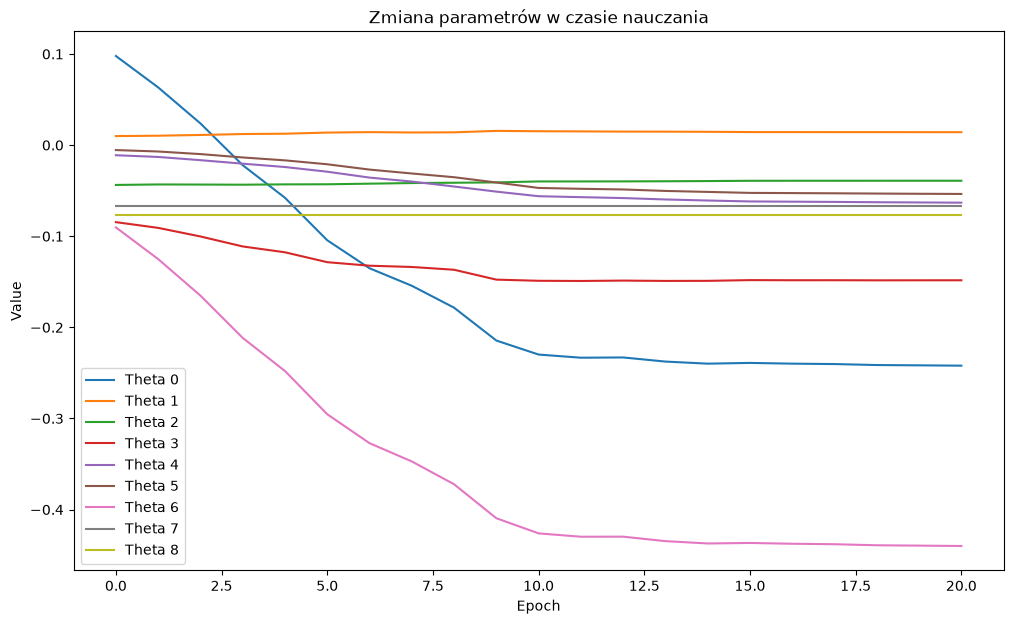

In [496]:
hist = history_1
th_history = np.array([e.params['th'] for e in hist])

from matplotlib import pyplot as plt
plt.figure(figsize=(12, 7))

for i in range(th_history.shape[1]):
    plt.plot(th_history[:, i], label=f'Theta {i}')

plt.legend()
plt.title('Zmiana parametrów w czasie nauczania')
plt.xlabel('Epoch')
plt.ylabel('Value');

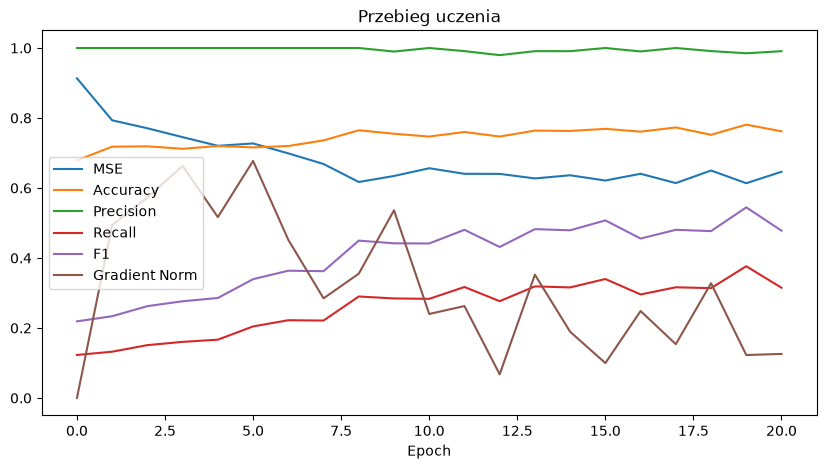

In [507]:
hist = history_1
plt.figure(figsize=(10, 5))
plt.title('Przebieg uczenia')
plt.xlabel('Epoch')
plt.plot([e.metrics_val.mse for e in hist], label='MSE')
plt.plot([e.metrics_val.accuracy for e in hist], label='Accuracy')
plt.plot([e.metrics_val.precision for e in hist], label='Precision')
plt.plot([e.metrics_val.recall for e in hist], label='Recall')
plt.plot([e.metrics_val.f1 for e in hist], label='F1')
plt.plot([e.metrics_val.gradient_norm for e in hist], label='Gradient Norm')
plt.legend();

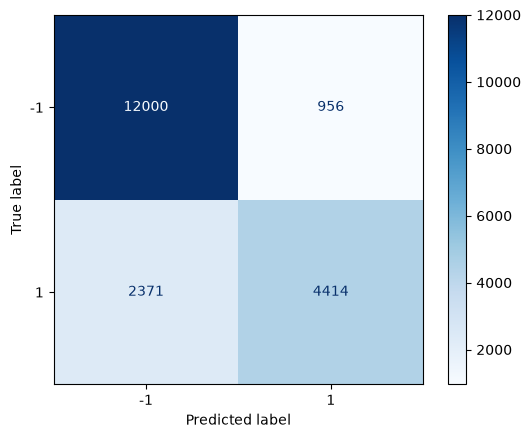

In [455]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, np.where(y_pred_test_1 >= treshold_1, 1, -1), labels=[-1, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[-1, 1]
).plot(cmap='Blues');